## ⚠️ Review notes — weaknesses found in the original notebook, and the fixes applied below


| # | Weakness in the original notebook | Fix applied below |
|---|---|---|
| 1 | **`generate_texts()` never actually generates any text — the critical bug.** It builds CLIP inputs, computes `image_features = clip_model.get_image_features(...)`, then **discards that result** and hardcodes `generated_text = "Generated text description"` for *every single image*. Every item in support/query/test gets the exact same string, so every "text embedding" fed into the fusion is identical. The text modality carries **zero information**, and the reported final accuracy (87.12% in the saved output) is effectively coming from the ViT branch alone — the "fusion of vision and text features" this notebook is supposed to demonstrate never happens. | Replaced with a real, image-conditioned text signal: CLIP zero-shot similarity against a bank of short histopathology descriptor phrases (see `CANDIDATE_DESCRIPTORS` below), keeping the top-k phrases per image as its "description." This is CLIP's actual intended use case (embedding-space retrieval), and the text now genuinely varies with image content. |
| 2 | **Conceptual misuse of CLIP as a caption generator.** CLIP has no text decoder — `get_image_features` only returns an embedding; it cannot produce free-text no matter what prompt is passed. The original code's intent (prompt CLIP and get a description back) could not have worked even without bug #1. | Same fix as #1: use CLIP for what it can do (image ⟷ text embedding similarity / retrieval), not text generation. |
| 3 | **Wrong feature space for the ViT half of the fusion** (same root cause as in `vit-based-fsl.ipynb`): `vit_model(images)` inside `extract_fused_features` returns the 2-unit classification logits, not an embedding, so a 2-D vector was being fused against a 384-d text vector. | `embed()` now returns the pooled 384-d pre-head ViT embedding (`forward_features` + `forward_head(..., pre_logits=True)`). |
| 4 | **Degenerate feature-relevance weighting, caused directly by #1.** `calculate_feature_relevance` divides between-class variance by within-class variance per dimension; with every text embedding identical, both variances are ~0 for every text dimension, so the Fisher-criterion weights for the text branch are meaningless noise gated only by the `+1e-10` epsilon. | Fixed automatically once #1 makes the text embeddings vary across images — the Fisher weighting now sees real between/within-class variance. |
| 5 | Same reproducibility, overfitting, accuracy-only-evaluation, hard-coded path, wasteful label-indexing and monolithic-cell issues as `vit-based-fsl.ipynb` (see that notebook for the detailed explanation of each). | Same fixes: `set_seed()`, `FREEZE_BACKBONE` shallow fine-tuning + weight decay + support-set augmentation, full analysis suite (`full_analysis`: heatmaps, ROC/PR, MCC, kappa, CIs, held-out-Test-only metrics, t-SNE), `resolve_raw_dir()`, `dataset.samples`-based indexing, narrated multi-cell structure. |
| 6 | **Un-batched, one-image-at-a-time inference.** `generate_texts` looped over the dataset one PIL image at a time through the CLIP processor/model, and the feature-extraction `DataLoader`s all used `batch_size=1`, despite nothing preventing batching. | `generate_texts` now batches images through CLIP (`EXTRACT_BATCH_SIZE` at a time); the ViT feature-extraction loaders also use `EXTRACT_BATCH_SIZE` instead of 1. |
| 7 | **Dead computation.** `clip_processor(images=img, text="<fixed prompt>", ...)` re-tokenized the exact same fixed sentence for every one of ~2000 images just to reach `.pixel_values` — the `text=`, `input_ids` and `attention_mask` outputs were never used. | The CLIP image processor is now called with `images=` only. |
| 8 | **Single episode only (no repeats), unlike the multi-episode setup added to `vit-based-fsl.ipynb`.** | Kept as a single run here on purpose: CLIP + SentenceTransformer text-feature extraction over ~2000 images is the expensive step, so repeating it `N_EPISODES` times has a real compute cost. The code is written so `N_EPISODES > 1` works if you have the budget — see the final cell — but it defaults to 1. |
| 9 | **No ablation.** The notebook never compared ViT-only vs text-only vs fused, so nothing in it could actually show that fusion helps (and with the placeholder text it could not have). | Added `modality_ablation()`, which scores prototype classification on ViT-only, text-only and fused features with the same support/query/test split and saves a comparison table. |
| 10 | README/paper claim results on BreakHis *and* BACH, but only BreakHis is present in this repo. | **Not fabricated here** — no BACH data to validate against. The BreakHis preparation code is BreakHis-specific (it parses BreakHis filenames for patient ids), so BACH would need its own preparation step; the rest of the pipeline is `ImageFolder`-based and dataset-agnostic. Left as an open gap. |
| 11 | **Patient-level leakage risk in the train/test split.** The notebook assumed a ready-made `Train/`/`Test/` folder of unknown provenance. BreakHis has 82 patients and ~24 images per patient per magnification; a random image-level split puts the same patient in both sets and inflates accuracy. | `prepare_breakhis_split()` builds the split from the raw dataset **by patient** (stratified by class, seeded, identical assignment across all magnifications), as symlinks. `verify_and_report_split()` asserts zero patient overlap and prints per-split image/patient counts. |
| 12 | **Query set shared patients with the support set.** The original query split was "all other Train images", i.e. from the same patients as the 5 support images. | Support shots come from distinct patients and the query set excludes every image of a support patient. |
| 13 | **No majority-class baseline; only one magnification.** BreakHis is ~70% malignant, so "always malignant" already scores ~70%. Only 200X was evaluated in the original. | Majority-class baseline is printed and stored next to accuracy; the run loops over `MAGNIFICATION_SETTINGS` (40X, 100X, 200X, 400X and all four combined) and prints a comparison table. |

In [2]:
import json
import os
import random
import re
import shutil
from collections import Counter, defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from timm import create_model
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm
from transformers import CLIPProcessor, CLIPModel
from sentence_transformers import SentenceTransformer


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Fix #6: portable dataset path with a clear error instead of an opaque failure.
def resolve_raw_dir():
    candidates = [
        os.environ.get("BREAKHIS_RAW_DIR", ""),
        "./dataset/classificacao_binaria",
        "./dataset/BreakHis/classificacao_binaria",
    ]
    for path in candidates:
        if path and os.path.isdir(path):
            return path
    raise FileNotFoundError(
        "Could not find the raw BreakHis folder (the one that contains 40X/ 100X/ 200X/ 400X/, each with "
        "benign/ and malignant/). Put it at ./dataset/classificacao_binaria or set BREAKHIS_RAW_DIR."
    )


RAW_DATA_DIR = resolve_raw_dir()

# Dataset preparation settings (see "Dataset preparation" below).
PREPARED_ROOT = "./data/BreakHist_patient_split"
MAGNIFICATION_SETTINGS = ["40X", "100X", "200X", "400X", "40X+100X+200X+400X"]  # "+" = train AND test on those magnifications together
SPLIT_SEED = 42
TEST_FRACTION = 0.3

# Hyperparameters
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 32
EXTRACT_BATCH_SIZE = 32   # Fix #6: batched instead of one-image-at-a-time inference
SHOTS_PER_CLASS = 5
TOP_K_DESCRIPTORS = 4     # how many descriptor phrases to keep per image (Fix #1)
N_EPISODES = 1            # see weakness #8 for why this defaults to 1 here
FREEZE_BACKBONE = True
BASE_SEED = 42


### Dataset preparation — patient-level split (Fix #11)

The raw dataset (`dataset/classificacao_binaria/<magnification>/<class>/*.png`) is real BreakHis (7,909 images, 82 patients) but ships **without a train/test split**. Splitting randomly by image would put images of the same patient in both Train and Test (BreakHis has ~24 images per patient per magnification), which inflates accuracy. So the split is done **by patient**: stratified by class, seeded, and computed once over all magnifications, so a patient is on the same side at 200X, at 400X and in the combined `40X+100X+200X+400X` setting. The result is written as symlinks (no data is copied) under `data/BreakHist_patient_split/Final <setting>/{Train,Test}/<class>/`, and `verify_and_report_split()` asserts there is zero patient overlap.

In [3]:
import numpy as np

_FILENAME_RE = re.compile(r"^SOB_([BM])_([A-Z]+)-(\d+)-([A-Za-z0-9]+)-(\d+)-(\d+)\.png$")


def patient_id(path):
    """Official BreakHis filenames look like SOB_B_A-14-22549AB-40-001.png ->
    patient 'A-14-22549AB'. (Verified on this dataset: exactly 82 distinct ids = 24 benign + 58 malignant patients.)"""
    m = _FILENAME_RE.match(os.path.basename(path))
    if m is None:
        raise ValueError(f"Not an official BreakHis filename, cannot recover patient id: {path}")
    _, subtype, year, slide, _, _ = m.groups()
    return f"{subtype}-{year}-{slide}"


def assign_patient_split(raw_dir, test_fraction, seed):
    """patient -> 'Train' / 'Test', stratified by class. Computed over ALL magnifications at once,
    so the same patient lands on the same side at 40X, 100X, 200X and 400X (no cross-magnification leakage)."""
    patients_by_class = defaultdict(set)
    for mag in sorted(os.listdir(raw_dir)):
        for cls in sorted(os.listdir(os.path.join(raw_dir, mag))):
            for fname in os.listdir(os.path.join(raw_dir, mag, cls)):
                patients_by_class[cls].add(patient_id(fname))

    rng = np.random.RandomState(seed)
    assignment = {}
    for cls, pats in sorted(patients_by_class.items()):
        pats = sorted(pats)
        rng.shuffle(pats)
        n_test = max(1, int(round(len(pats) * test_fraction)))
        for i, p in enumerate(pats):
            assignment[p] = "Test" if i < n_test else "Train"
    return assignment


def prepare_breakhis_split(raw_dir, out_root, setting, test_fraction=0.3, seed=42):
    """Builds out_root/'Final <setting>'/{Train,Test}/<class>/ as symlinks to the raw images (no data copied).
    `setting` is a magnification such as '200X', or several joined with '+' such as '200X+400X'."""
    mags = setting.split("+")
    for mag in mags:
        if not os.path.isdir(os.path.join(raw_dir, mag)):
            raise FileNotFoundError(f"Magnification folder '{mag}' not found under {raw_dir}")

    out_dir = os.path.join(out_root, f"Final {setting}")
    manifest_path = os.path.join(out_dir, "split_manifest.json")
    params = {"mags": mags, "test_fraction": test_fraction, "seed": seed, "raw_dir": os.path.abspath(raw_dir)}

    if os.path.isfile(manifest_path):
        with open(manifest_path) as f:
            if json.load(f)["params"] == params:
                return out_dir
        shutil.rmtree(out_dir)  # stale split made by this function with other parameters (only symlinks inside)
    elif os.path.exists(out_dir):
        raise FileExistsError(f"{out_dir} exists but has no split_manifest.json; refusing to overwrite it.")

    assignment = assign_patient_split(raw_dir, test_fraction, seed)
    for mag in mags:
        for cls in sorted(os.listdir(os.path.join(raw_dir, mag))):
            src_dir = os.path.join(raw_dir, mag, cls)
            for fname in sorted(os.listdir(src_dir)):
                dst_dir = os.path.join(out_dir, assignment[patient_id(fname)], cls)
                os.makedirs(dst_dir, exist_ok=True)
                src, dst = os.path.abspath(os.path.join(src_dir, fname)), os.path.join(dst_dir, fname)
                try:
                    os.symlink(src, dst)
                except OSError:  # e.g. Windows without symlink rights
                    shutil.copy2(src, dst)

    with open(manifest_path, "w") as f:
        json.dump({"params": params, "assignment": assignment}, f)
    return out_dir


def verify_and_report_split(data_dir):
    """Asserts no patient appears in both Train and Test, and prints what the split looks like."""
    counts, patients = {}, {}
    print(f"{'split':<6} {'class':<12} {'images':>7} {'patients':>9}")
    for split in ("Train", "Test"):
        patients[split] = set()
        for cls in sorted(os.listdir(os.path.join(data_dir, split))):
            files = os.listdir(os.path.join(data_dir, split, cls))
            pats = {patient_id(f) for f in files}
            patients[split] |= pats
            counts[(split, cls)] = len(files)
            print(f"{split:<6} {cls:<12} {len(files):>7} {len(pats):>9}")

    overlap = patients["Train"] & patients["Test"]
    assert not overlap, f"PATIENT LEAKAGE: {len(overlap)} patients in both Train and Test: {sorted(overlap)[:5]}"
    test_counts = [n for (split, _), n in counts.items() if split == "Test"]
    print(f"OK: 0 patients shared between Train ({len(patients['Train'])}) and Test ({len(patients['Test'])}).")
    print(f"Majority-class baseline on Test: {100 * max(test_counts) / sum(test_counts):.1f}% accuracy (a model must beat this).")


### Data

`load_datasets()` opens the prepared patient-level `Train/` split twice on the ViT side (augmented for training, clean for embeddings/prototypes), plus the CLIP-side view used only to build text descriptions from images, plus the patient-disjoint `Test/` split. It is called once per magnification setting in the final cell.

In [4]:
# Fix #5 (augmentation): light augmentation for the ViT support-set training view;
# eval view stays clean/deterministic.
train_transform_vit = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

eval_transform_vit = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

# CLIP does its own resizing/normalization internally when given PIL images,
# so this transform only needs to resize.
transform_clip = transforms.Compose([
    transforms.Resize((224, 224)),
])

def load_datasets(data_dir):
    train_vit_aug = ImageFolder(root=f"{data_dir}/Train", transform=train_transform_vit)
    train_vit_eval = ImageFolder(root=f"{data_dir}/Train", transform=eval_transform_vit)
    test_vit = ImageFolder(root=f"{data_dir}/Test", transform=eval_transform_vit)
    train_clip = ImageFolder(root=f"{data_dir}/Train", transform=transform_clip)
    test_clip = ImageFolder(root=f"{data_dir}/Test", transform=transform_clip)
    assert train_vit_aug.classes == train_vit_eval.classes == test_vit.classes == train_clip.classes == test_clip.classes
    return train_vit_aug, train_vit_eval, test_vit, train_clip, test_clip, train_vit_eval.classes


### Models

`embed()` is Fix #3 (pooled pre-head ViT embedding instead of classifier logits). `clip_processor`/`clip_model` are used only for zero-shot image↔text similarity (Fix #1/#2), never as a caption generator. `text_encoder` embeds the resulting phrase strings.

In [5]:
def build_vit_model():
    model = create_model('vit_small_patch16_224', pretrained=True)
    model.head = nn.Linear(model.num_features, len(class_names))
    model.to(device)
    return model


def freeze_backbone_except_last_block(model, unfreeze_last_n_blocks: int = 1):
    """Fix #5: shallow fine-tuning instead of full-backbone fine-tuning on 10 images."""
    for param in model.parameters():
        param.requires_grad = False
    for param in model.head.parameters():
        param.requires_grad = True
    for block in model.blocks[-unfreeze_last_n_blocks:]:
        for param in block.parameters():
            param.requires_grad = True
    for param in model.norm.parameters():
        param.requires_grad = True


def embed(model, images):
    """Fix #3: pooled pre-logits ViT embedding, NOT the classification-head logits
    that the original `extract_fused_features` used via a bare `model(images)` call."""
    features = model.forward_features(images)
    pooled = model.forward_head(features, pre_logits=True)
    return pooled


clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
text_encoder = SentenceTransformer('all-MiniLM-L6-v2').to(device)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

### Feature-fusion helpers

Unchanged from the original notebook — this logic itself wasn't buggy, it was just being fed a constant, uninformative text vector (weakness #1/#4). Once the text embeddings below actually vary per image, this Fisher-criterion weighting becomes meaningful.

In [6]:
def calculate_feature_relevance(features, labels):
    """
    Calculate feature relevance using Fisher's criterion for each feature dimension
    """
    unique_labels = np.unique(labels)
    n_features = features.shape[1]
    relevance_scores = np.zeros(n_features)

    for i in range(n_features):
        feature_i = features[:, i]

        # Calculate mean and variance for each class
        class_means = np.array([np.mean(feature_i[labels == label]) for label in unique_labels])
        class_vars = np.array([np.var(feature_i[labels == label]) for label in unique_labels])

        # Fisher's criterion: inter-class variance / intra-class variance
        between_class_var = np.var(class_means)
        within_class_var = np.mean(class_vars)

        # Avoid division by zero
        relevance_scores[i] = between_class_var / (within_class_var + 1e-10)

    # Normalize scores
    return relevance_scores / (np.sum(relevance_scores) + 1e-10)


def calculate_feature_similarity(vit_features, clip_features):
    """
    Calculate similarity between ViT and text features using canonical correlation analysis
    """
    vit_norm = vit_features - np.mean(vit_features, axis=0)
    clip_norm = clip_features - np.mean(clip_features, axis=0)

    corr_matrix = np.dot(vit_norm.T, clip_norm) / (vit_features.shape[0] - 1)

    similarity_scores = np.abs(np.diag(corr_matrix))
    return similarity_scores / (np.sum(similarity_scores) + 1e-10)


def weighted_feature_fusion(vit_features, clip_features, labels=None):
    """
    Perform weighted feature fusion using relevance and similarity metrics
    """
    if labels is not None:
        vit_relevance = calculate_feature_relevance(vit_features, labels)
        clip_relevance = calculate_feature_relevance(clip_features, labels)
    else:
        vit_relevance = np.ones(vit_features.shape[1]) / vit_features.shape[1]
        clip_relevance = np.ones(clip_features.shape[1]) / clip_features.shape[1]

    similarity_scores = calculate_feature_similarity(vit_features, clip_features)

    vit_weights = vit_relevance * np.mean(similarity_scores)
    clip_weights = clip_relevance * np.mean(similarity_scores)

    vit_weights = vit_weights / (np.sum(vit_weights) + 1e-10)
    clip_weights = clip_weights / (np.sum(clip_weights) + 1e-10)

    fused_features = np.concatenate([
        vit_features * vit_weights.reshape(1, -1),
        clip_features * clip_weights.reshape(1, -1)
    ], axis=1)

    return fused_features


### Text generation — Fix #1 / #2 (the critical bug)

The original `generate_texts()` called `clip_model.get_image_features(...)`, threw the result away, and appended the literal string `"Generated text description"` for every image — so every image, in every split, got identical text. CLIP also has no text decoder, so even a "working" version of that function could never have produced a real caption.

The fix below uses CLIP the way it's actually designed to be used: as an image↔text embedding-similarity model. A small bank of generic histopathology descriptor phrases is embedded once; for each image, the top-`k` closest phrases by cosine similarity become that image's "description." The phrases never mention the class names, so no ground-truth label leaks into query/test text through this step.

In [7]:
# Generic morphological descriptor phrases (no class names) -- Fix #1.
CANDIDATE_DESCRIPTORS = [
    "densely packed epithelial cells",
    "uniform, evenly spaced nuclei",
    "irregular and enlarged nuclei",
    "high nuclear-to-cytoplasmic ratio",
    "well-defined duct-like structures",
    "disorganized tissue architecture",
    "prominent nucleoli",
    "increased mitotic figures",
    "sparse, loosely arranged cells",
    "infiltrating cell clusters",
    "smooth, rounded cell borders",
    "irregular, jagged cell borders",
    "homogeneous pink-stained cytoplasm",
    "areas of necrosis",
    "fibrous stromal tissue",
    "clear cell boundaries with visible nucleoli",
]


def _as_tensor(out):
    """transformers >= 5 returns an output object from CLIP's get_*_features (projected embedding in
    `.pooler_output`); older versions return the tensor directly. Support both."""
    return out.pooler_output if hasattr(out, "pooler_output") else out


def build_clip_text_bank():
    with torch.no_grad():
        inputs = clip_processor(text=CANDIDATE_DESCRIPTORS, return_tensors="pt", padding=True).to(device)
        text_features = _as_tensor(clip_model.get_text_features(**inputs))
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)
    return text_features  # (num_phrases, dim)


def generate_texts(dataset, text_bank, top_k=TOP_K_DESCRIPTORS, batch_size=EXTRACT_BATCH_SIZE):
    """Fix #1/#2 + #6: batched CLIP zero-shot phrase retrieval instead of a
    constant placeholder string generated one image at a time."""
    texts = []
    clip_model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=lambda batch: batch)

    with torch.no_grad():
        for batch in tqdm(loader, desc="Generating texts"):
            pil_images = []
            for img, _ in batch:
                if isinstance(img, torch.Tensor):
                    img = transforms.ToPILImage()(img)
                pil_images.append(img)

            inputs = clip_processor(images=pil_images, return_tensors="pt").to(device)
            image_features = _as_tensor(clip_model.get_image_features(pixel_values=inputs.pixel_values))
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)

            similarities = image_features @ text_bank.T  # (batch, num_phrases)
            top_indices = torch.topk(similarities, k=top_k, dim=1).indices.tolist()
            for idxs in top_indices:
                texts.append(", ".join(CANDIDATE_DESCRIPTORS[i] for i in idxs))
    return texts


def encode_texts(texts):
    return text_encoder.encode(texts, convert_to_tensor=True, device=device).cpu().numpy()


### Episode sampling, training, fused feature extraction and evaluation

Helper functions only — the actual run is the final cell.

In [8]:
def create_support_and_query(dataset, shots_per_class, rng):
    """Fix #8 + #12: labels come from `dataset.samples` (no image decoding). Support shots are drawn from
    DISTINCT patients, and the query set excludes every image of a support patient -- otherwise the query
    images would come from the same patients as the support images and inflate accuracy."""
    by_class = {label: [] for label in range(len(dataset.classes))}
    for idx, (path, label) in enumerate(dataset.samples):
        by_class[label].append((idx, patient_id(path)))

    support_indices, support_patients = [], set()
    for label, items in by_class.items():
        chosen = set()
        for k in rng.permutation(len(items)):
            idx, pid = items[k]
            if pid in chosen:
                continue
            chosen.add(pid)
            support_indices.append(idx)
            if len(chosen) == shots_per_class:
                break
        assert len(chosen) == shots_per_class, f"class {label} has fewer than {shots_per_class} patients"
        support_patients |= chosen

    query_indices = [idx for items in by_class.values() for idx, pid in items if pid not in support_patients]
    return support_indices, query_indices


def train_model_on_support(model, support_loader, num_epochs, lr, weight_decay):
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(trainable_params, lr=lr, weight_decay=weight_decay)
    history = {"loss": [], "support_acc": []}

    for epoch in range(num_epochs):
        model.train()
        epoch_loss, correct, total = 0.0, 0, 0
        for images, labels in support_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            epoch_loss += loss.item()

        history["loss"].append(epoch_loss / len(support_loader))
        history["support_acc"].append(100 * correct / total)
        if (epoch + 1) % 10 == 0 or epoch == num_epochs - 1:
            print(f"  epoch {epoch+1}/{num_epochs} - loss {epoch_loss:.4f} - support-set acc {100*correct/total:.1f}%")
    return model, history


def extract_fused_features(model, loader, text_features, labels=None):
    vit_features, all_labels = [], []
    model.eval()

    with torch.no_grad():
        for images, targets in tqdm(loader, desc="Extracting ViT features", leave=False):
            images = images.to(device)
            feats = embed(model, images).cpu().numpy()  # Fix #3: embedding, not logits
            vit_features.append(feats)
            all_labels.append(targets.numpy())

    vit_features = np.vstack(vit_features)
    all_labels = np.hstack(all_labels)

    fused_features = weighted_feature_fusion(vit_features, text_features, labels)
    return fused_features, all_labels, vit_features


def prototype_similarities(support_x, support_y, eval_x):
    protos = np.array([support_x[support_y == l].mean(axis=0) for l in np.unique(support_y)])
    return cosine_similarity(eval_x, protos)


def evaluate_fused(support_fused, support_labels, query_fused, query_labels, test_fused, test_labels):
    all_features = np.vstack([query_fused, test_fused])
    all_labels = np.concatenate([query_labels, test_labels])
    similarities = prototype_similarities(support_fused, support_labels, all_features)
    predictions = np.argmax(similarities, axis=1)
    return all_labels, predictions, similarities, all_features, len(query_labels)


def modality_ablation(support, query, test, support_labels, all_labels, n_query, class_names, tag):
    """`support`/`query`/`test` are dicts of feature matrices keyed by 'vit', 'text', 'fused'.
    Same split, same prototype classifier -- only the feature source changes."""
    rows = {}
    for name in ("vit", "text", "fused"):
        x = np.vstack([query[name], test[name]])
        sims = prototype_similarities(support[name], support_labels, x)
        pred = sims.argmax(axis=1)
        m = compute_metrics(all_labels, pred, similarities_to_probs(sims), len(class_names), n_boot=0)
        tm = compute_metrics(all_labels[n_query:], pred[n_query:], similarities_to_probs(sims)[n_query:], len(class_names), n_boot=0)
        rows[name] = {"accuracy": m["accuracy"], "f1_macro": m["f1_macro"], "roc_auc": m["roc_auc"], "mcc": m["mcc"],
                      "test_only_accuracy": tm["accuracy"], "test_only_roc_auc": tm["roc_auc"]}
    df = pd.DataFrame(rows).T
    print(f"\n----- {tag}: modality ablation (ViT-only vs text-only vs fused) -----")
    print(df.round(4).to_string())
    os.makedirs(RESULTS_DIR, exist_ok=True)
    df.to_csv(f"{RESULTS_DIR}/{tag}_ablation.csv")
    ax = df[["accuracy", "f1_macro", "roc_auc"]].plot.bar(figsize=(7, 4), rot=0, ylim=(0, 1.05), title=f"{tag}: modality ablation")
    ax.figure.tight_layout()
    ax.figure.savefig(f"{RESULTS_DIR}/{tag}_ablation.png", dpi=150)
    plt.show()
    return df


### Results analysis suite

The original notebook reported a single accuracy number. `full_analysis()` now produces, per episode: precision/recall/F1 per class, accuracy, balanced accuracy, macro/weighted F1, MCC, Cohen's kappa, ROC-AUC, average precision, sensitivity/specificity (binary), bootstrap 95% CIs for accuracy and AUC, **Test-only** metrics (the `Test/` split is patient-disjoint from all of `Train/`; the query split is patient-disjoint from the support set), the **majority-class baseline** (accuracy of always predicting the most frequent class), and a figure with confusion-matrix heatmaps (counts + row-normalised), ROC curve, precision-recall curve, fine-tuning curve and a t-SNE of the embeddings with misclassified samples marked. Figures / JSON / CSV are saved under `results/`.

ROC/PR need class scores, but this is a prototype classifier, so `similarities_to_probs()` applies a softmax over the cosine similarities to the class prototypes (monotonic, so predictions and AUC ranking are unaffected). For binary BreakHis the positive class is the second alphabetical folder (`malignant`).

The fusion notebook additionally runs `modality_ablation()` (defined in the helpers cell above) to show whether fusion actually beats either modality alone.

In [9]:
import os

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import json

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, cohen_kappa_score,
    auc, matthews_corrcoef, precision_recall_curve, precision_recall_fscore_support,
    roc_auc_score, roc_curve,
)
from sklearn.preprocessing import label_binarize

RESULTS_DIR = "results"
PLOT_TSNE = True


def similarities_to_probs(similarities, temperature=20.0):
    """Softmax over cosine similarities so ROC/PR/AUC have class scores to work with.
    (Monotonic per row, so it never changes the argmax prediction or the AUC ranking.)"""
    z = similarities * temperature
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def _auc(y_true, y_prob, n_classes):
    if n_classes == 2:
        return roc_auc_score(y_true, y_prob[:, 1])
    return roc_auc_score(y_true, y_prob, multi_class="ovr", labels=list(range(n_classes)))


def compute_metrics(y_true, y_pred, y_prob, n_classes, n_boot=1000, seed=0):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    _, _, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    p_macro, r_macro, _, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, f1_weighted, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "mcc": matthews_corrcoef(y_true, y_pred),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
        "roc_auc": _auc(y_true, y_prob, n_classes),
    }
    if n_classes == 2:
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        m["sensitivity"] = tp / (tp + fn) if (tp + fn) else 0.0
        m["specificity"] = tn / (tn + fp) if (tn + fp) else 0.0
        m["avg_precision"] = average_precision_score(y_true, y_prob[:, 1])

    if n_boot:
        rng = np.random.RandomState(seed)
        n = len(y_true)
        accs, aucs = [], []
        for _ in range(n_boot):
            idx = rng.randint(0, n, n)
            accs.append(accuracy_score(y_true[idx], y_pred[idx]))
            if len(np.unique(y_true[idx])) == n_classes:
                aucs.append(_auc(y_true[idx], y_prob[idx], n_classes))
        m["accuracy_ci95"] = tuple(np.percentile(accs, [2.5, 97.5]))
        m["roc_auc_ci95"] = tuple(np.percentile(aucs, [2.5, 97.5])) if aucs else (np.nan, np.nan)
    return m


def _heatmap(ax, mat, class_names, title, fmt, vmax):
    im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticks(range(len(class_names)))
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center",
                    color="white" if mat[i, j] > vmax / 2 else "black")
    plt.colorbar(im, ax=ax, fraction=0.046)


def full_analysis(y_true, y_pred, y_prob, class_names, tag, features=None, history=None, n_query=None):
    """Prints a full metric report and saves a 2x3 figure: confusion-matrix heatmaps
    (counts + row-normalised), ROC, precision-recall, training curve, t-SNE."""
    os.makedirs(RESULTS_DIR, exist_ok=True)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(class_names)
    metrics = compute_metrics(y_true, y_pred, y_prob, n)
    metrics["majority_class_baseline"] = np.bincount(y_true).max() / len(y_true)

    if n_query is not None:  # Test/ split only (patient-disjoint from all of Train/)
        tm = compute_metrics(y_true[n_query:], y_pred[n_query:], y_prob[n_query:], n, n_boot=0)
        for k in ("accuracy", "balanced_accuracy", "f1_macro", "roc_auc"):
            metrics[f"test_only_{k}"] = tm[k]
        metrics["test_only_majority_class_baseline"] = np.bincount(y_true[n_query:], minlength=n).max() / len(y_true[n_query:])

    print(f"\n----- {tag} -----")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
    for k, v in metrics.items():
        print(f"  {k:>24}: " + (f"[{v[0]:.4f}, {v[1]:.4f}]" if isinstance(v, tuple) else f"{v:.4f}"))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(n)))
    cm_norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

    fig, axes = plt.subplots(2, 3, figsize=(19, 11))
    _heatmap(axes[0, 0], cm, class_names, "Confusion matrix (counts)", "d", max(cm.max(), 1))
    _heatmap(axes[0, 1], cm_norm, class_names, "Confusion matrix (row-normalised)", ".2f", 1.0)

    ax_roc, ax_pr = axes[0, 2], axes[1, 0]
    if n == 2:
        fpr, tpr, _ = roc_curve(y_true, y_prob[:, 1])
        ax_roc.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}  (positive = '{class_names[1]}')")
        prec, rec, _ = precision_recall_curve(y_true, y_prob[:, 1])
        ax_pr.plot(rec, prec, label=f"AP = {average_precision_score(y_true, y_prob[:, 1]):.3f}")
    else:
        y_bin = label_binarize(y_true, classes=list(range(n)))
        for c in range(n):
            fpr, tpr, _ = roc_curve(y_bin[:, c], y_prob[:, c])
            ax_roc.plot(fpr, tpr, label=f"{class_names[c]} (AUC = {auc(fpr, tpr):.3f})")
            prec, rec, _ = precision_recall_curve(y_bin[:, c], y_prob[:, c])
            ax_pr.plot(rec, prec, label=f"{class_names[c]} (AP = {average_precision_score(y_bin[:, c], y_prob[:, c]):.3f})")
    ax_roc.plot([0, 1], [0, 1], "k--", lw=1)
    ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
    ax_roc.legend(loc="lower right")
    ax_pr.set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
    ax_pr.legend(loc="lower left")

    ax_hist = axes[1, 1]
    if history:
        ax_hist.plot(history["loss"], color="tab:red", label="support loss")
        ax_hist.set(xlabel="Epoch", ylabel="Loss", title="Fine-tuning curve (support set)")
        ax2 = ax_hist.twinx()
        ax2.plot(history["support_acc"], color="tab:green", label="support acc")
        ax2.set_ylabel("Support-set accuracy (%)")
    else:
        ax_hist.axis("off")

    ax_tsne = axes[1, 2]
    if features is not None and PLOT_TSNE:
        rng = np.random.RandomState(0)
        sub = rng.choice(len(features), size=min(2000, len(features)), replace=False)
        emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(features[sub])
        wrong = y_true[sub] != y_pred[sub]
        for c in range(n):
            mask = (y_true[sub] == c) & ~wrong
            ax_tsne.scatter(emb[mask, 0], emb[mask, 1], s=8, alpha=0.6, label=class_names[c])
        ax_tsne.scatter(emb[wrong, 0], emb[wrong, 1], s=22, marker="x", c="k", label="misclassified")
        ax_tsne.set_title("t-SNE of embeddings")
        ax_tsne.legend()
    else:
        ax_tsne.axis("off")

    fig.suptitle(tag, fontsize=14)
    fig.tight_layout()
    fig.savefig(f"{RESULTS_DIR}/{tag}_analysis.png", dpi=150)
    plt.show()

    with open(f"{RESULTS_DIR}/{tag}_metrics.json", "w") as f:
        json.dump(metrics, f, indent=2, default=float)
    return metrics


def summarize_episodes(all_metrics, tag):
    df = pd.DataFrame([{k: v for k, v in m.items() if not k.endswith("ci95")} for m in all_metrics])
    summary = pd.DataFrame({"mean": df.mean(), "std": df.std(ddof=0)})
    print(f"\n===== {tag}: summary over {len(all_metrics)} episode(s) =====")
    print(summary.round(4).to_string())
    os.makedirs(RESULTS_DIR, exist_ok=True)
    df.to_csv(f"{RESULTS_DIR}/{tag}_per_episode_metrics.csv", index=False)
    summary.to_csv(f"{RESULTS_DIR}/{tag}_summary.csv")
    return summary


### Run over magnification settings

For each entry of `MAGNIFICATION_SETTINGS` (40X, 100X, 200X, 400X, and all four combined) this builds the patient-level split and runs the pipeline. `N_EPISODES` defaults to 1 (weakness #8) since CLIP text generation over the whole split is the expensive step; raise it if you have the compute budget to also get mean ± std like `vit-based-fsl.ipynb`.


########################################################################
# Magnification setting: 40X
########################################################################
split  class         images  patients
Train  benign           486        17
Train  malignant        960        41
Test   benign           139         7
Test   malignant        410        17
OK: 0 patients shared between Train (58) and Test (24).
Majority-class baseline on Test: 74.7% accuracy (a model must beat this).
Classes: ['benign', 'malignant']

=== [40X] Episode 1/1 (seed=42) ===
support: 10 images | query: 1147 images (patient-disjoint from support)
Generating support set texts...


Generating texts: 100%|██████████| 1/1 [00:00<00:00,  7.54it/s]


Generating query set texts...


Generating texts: 100%|██████████| 36/36 [00:03<00:00, 11.71it/s]


Generating test set texts...


Generating texts: 100%|██████████| 18/18 [00:01<00:00, 10.67it/s]


Example generated descriptions: ['fibrous stromal tissue, homogeneous pink-stained cytoplasm, densely packed epithelial cells, smooth, rounded cell borders', 'fibrous stromal tissue, homogeneous pink-stained cytoplasm, densely packed epithelial cells, sparse, loosely arranged cells']
Encoding texts...
Training model on support set...
  epoch 10/50 - loss 0.4384 - support-set acc 70.0%
  epoch 20/50 - loss 0.0494 - support-set acc 100.0%
  epoch 30/50 - loss 0.0041 - support-set acc 100.0%
  epoch 40/50 - loss 0.0010 - support-set acc 100.0%
  epoch 50/50 - loss 0.0011 - support-set acc 100.0%
Extracting fused support set features...


Extracting fused query set features...


Extracting fused test set features...



----- fusion_fsl_40X_episode0 -----
              precision    recall  f1-score   support

      benign      0.744     0.479     0.583       461
   malignant      0.828     0.938     0.880      1235

    accuracy                          0.814      1696
   macro avg      0.786     0.709     0.732      1696
weighted avg      0.806     0.814     0.799      1696

                  accuracy: 0.8137
         balanced_accuracy: 0.7089
           precision_macro: 0.7863
              recall_macro: 0.7089
                  f1_macro: 0.7316
               f1_weighted: 0.7993
                       mcc: 0.4891
               cohen_kappa: 0.4703
                   roc_auc: 0.8591
               sensitivity: 0.9385
               specificity: 0.4794
             avg_precision: 0.9353
             accuracy_ci95: [0.7948, 0.8314]
              roc_auc_ci95: [0.8395, 0.8782]
   majority_class_baseline: 0.7282
        test_only_accuracy: 0.8324
  test_only_balanced_accuracy: 0.7380
        test_only_

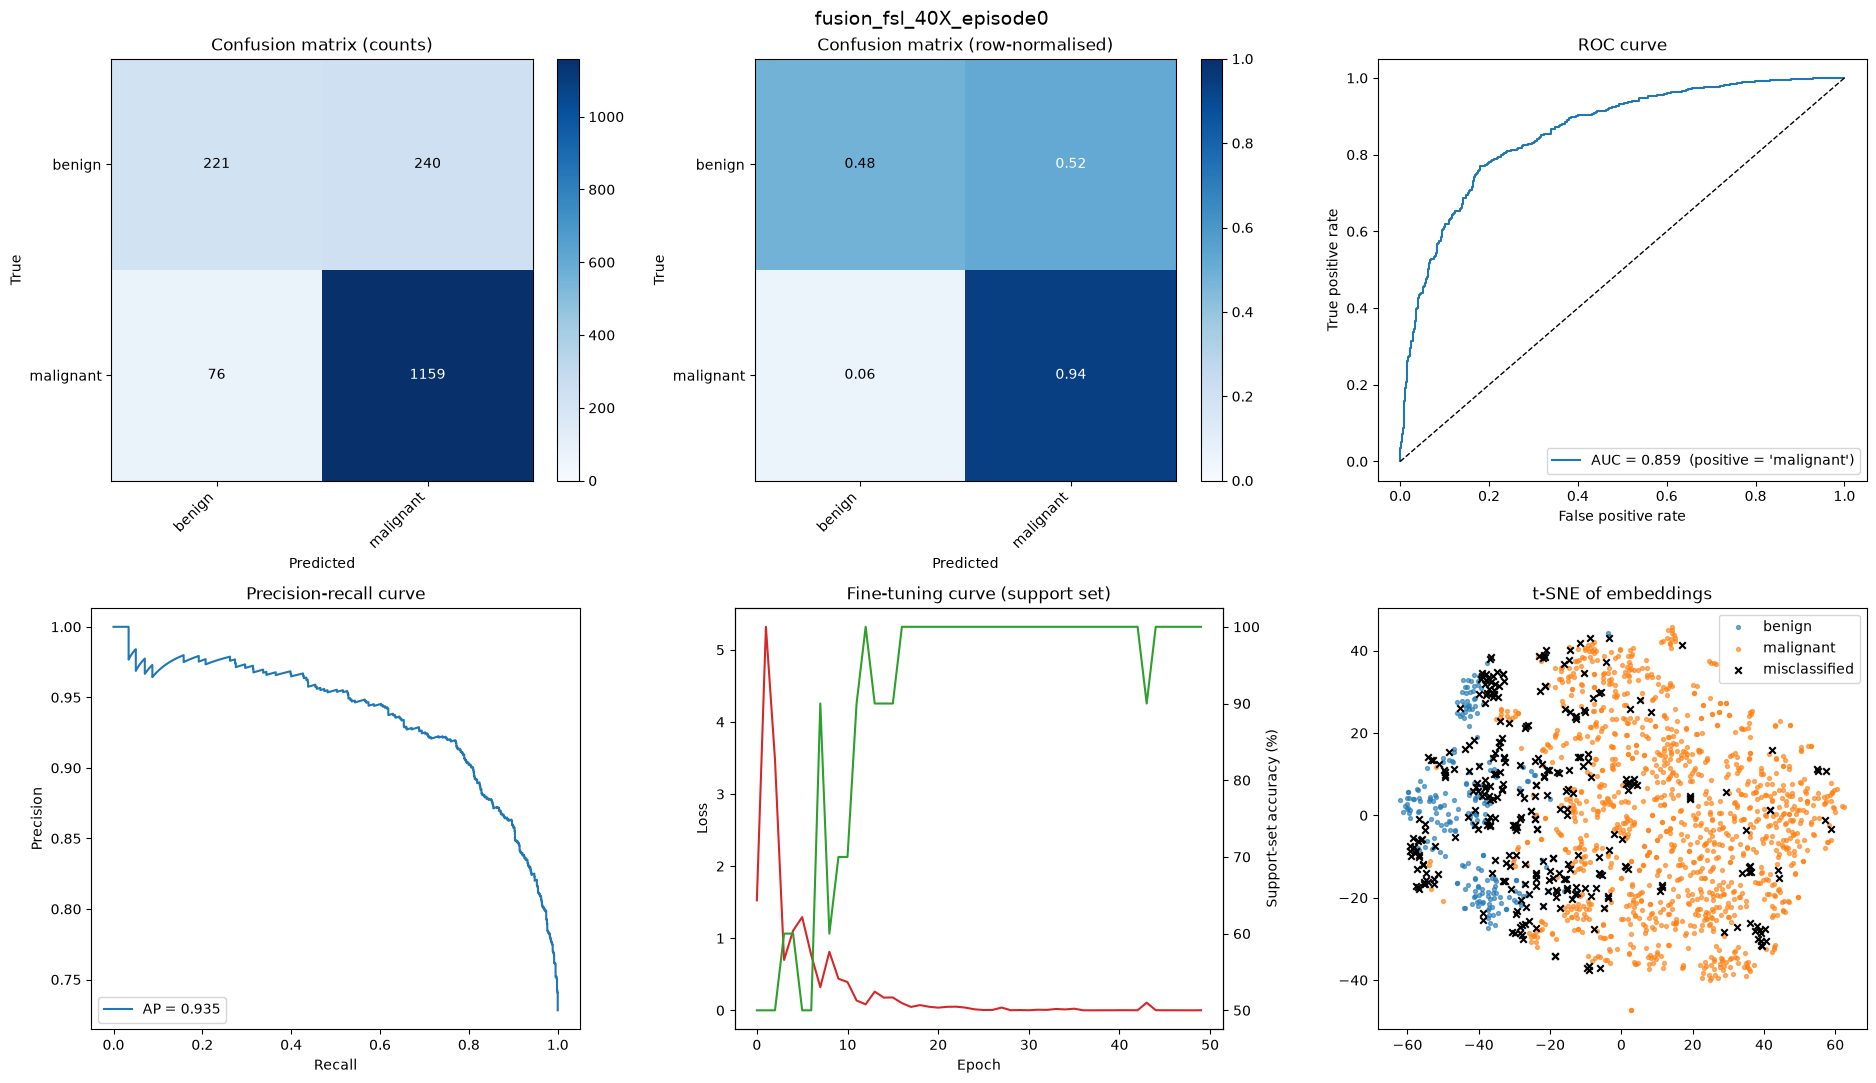


----- fusion_fsl_40X_episode0: modality ablation (ViT-only vs text-only vs fused) -----
       accuracy  f1_macro  roc_auc     mcc  test_only_accuracy  test_only_roc_auc
vit      0.8172    0.7442   0.8588  0.5047              0.8306             0.8753
text     0.7223    0.5595   0.6396  0.1693              0.7359             0.6728
fused    0.8137    0.7316   0.8591  0.4891              0.8324             0.8747


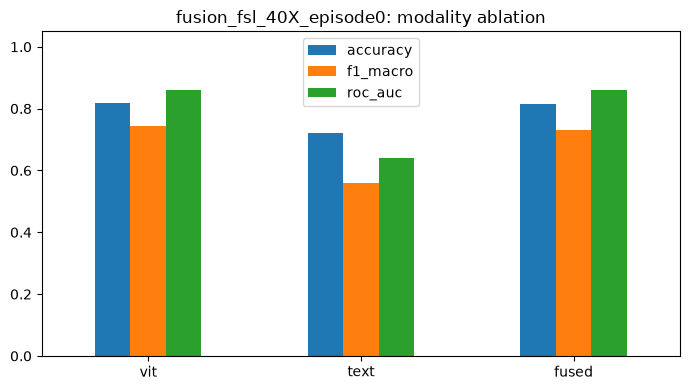


===== fusion_fsl_40X: summary over 1 episode(s) =====
                                     mean  std
accuracy                           0.8137  0.0
balanced_accuracy                  0.7089  0.0
precision_macro                    0.7863  0.0
recall_macro                       0.7089  0.0
f1_macro                           0.7316  0.0
f1_weighted                        0.7993  0.0
mcc                                0.4891  0.0
cohen_kappa                        0.4703  0.0
roc_auc                            0.8591  0.0
sensitivity                        0.9385  0.0
specificity                        0.4794  0.0
avg_precision                      0.9353  0.0
majority_class_baseline            0.7282  0.0
test_only_accuracy                 0.8324  0.0
test_only_balanced_accuracy        0.7380  0.0
test_only_f1_macro                 0.7576  0.0
test_only_roc_auc                  0.8747  0.0
test_only_majority_class_baseline  0.7468  0.0

###################################################

Generating texts: 100%|██████████| 1/1 [00:00<00:00, 27.93it/s]


Generating query set texts...


Generating texts: 100%|██████████| 37/37 [00:04<00:00,  9.10it/s]


Generating test set texts...


Generating texts: 100%|██████████| 18/18 [00:01<00:00,  9.57it/s]


Example generated descriptions: ['fibrous stromal tissue, homogeneous pink-stained cytoplasm, densely packed epithelial cells, smooth, rounded cell borders', 'fibrous stromal tissue, homogeneous pink-stained cytoplasm, densely packed epithelial cells, smooth, rounded cell borders']
Encoding texts...
Training model on support set...
  epoch 10/50 - loss 0.2876 - support-set acc 80.0%
  epoch 20/50 - loss 0.0257 - support-set acc 100.0%
  epoch 30/50 - loss 0.0016 - support-set acc 100.0%
  epoch 40/50 - loss 0.0004 - support-set acc 100.0%
  epoch 50/50 - loss 0.0001 - support-set acc 100.0%
Extracting fused support set features...


Extracting fused query set features...


Extracting fused test set features...



----- fusion_fsl_100X_episode0 -----
              precision    recall  f1-score   support

      benign      0.377     0.853     0.523       475
   malignant      0.896     0.474     0.620      1270

    accuracy                          0.577      1745
   macro avg      0.637     0.663     0.572      1745
weighted avg      0.755     0.577     0.594      1745

                  accuracy: 0.5771
         balanced_accuracy: 0.6633
           precision_macro: 0.6366
              recall_macro: 0.6633
                  f1_macro: 0.5716
               f1_weighted: 0.5937
                       mcc: 0.2988
               cohen_kappa: 0.2343
                   roc_auc: 0.7571
               sensitivity: 0.4740
               specificity: 0.8526
             avg_precision: 0.8921
             accuracy_ci95: [0.5536, 0.6006]
              roc_auc_ci95: [0.7328, 0.7797]
   majority_class_baseline: 0.7278
        test_only_accuracy: 0.6364
  test_only_balanced_accuracy: 0.7022
        test_only

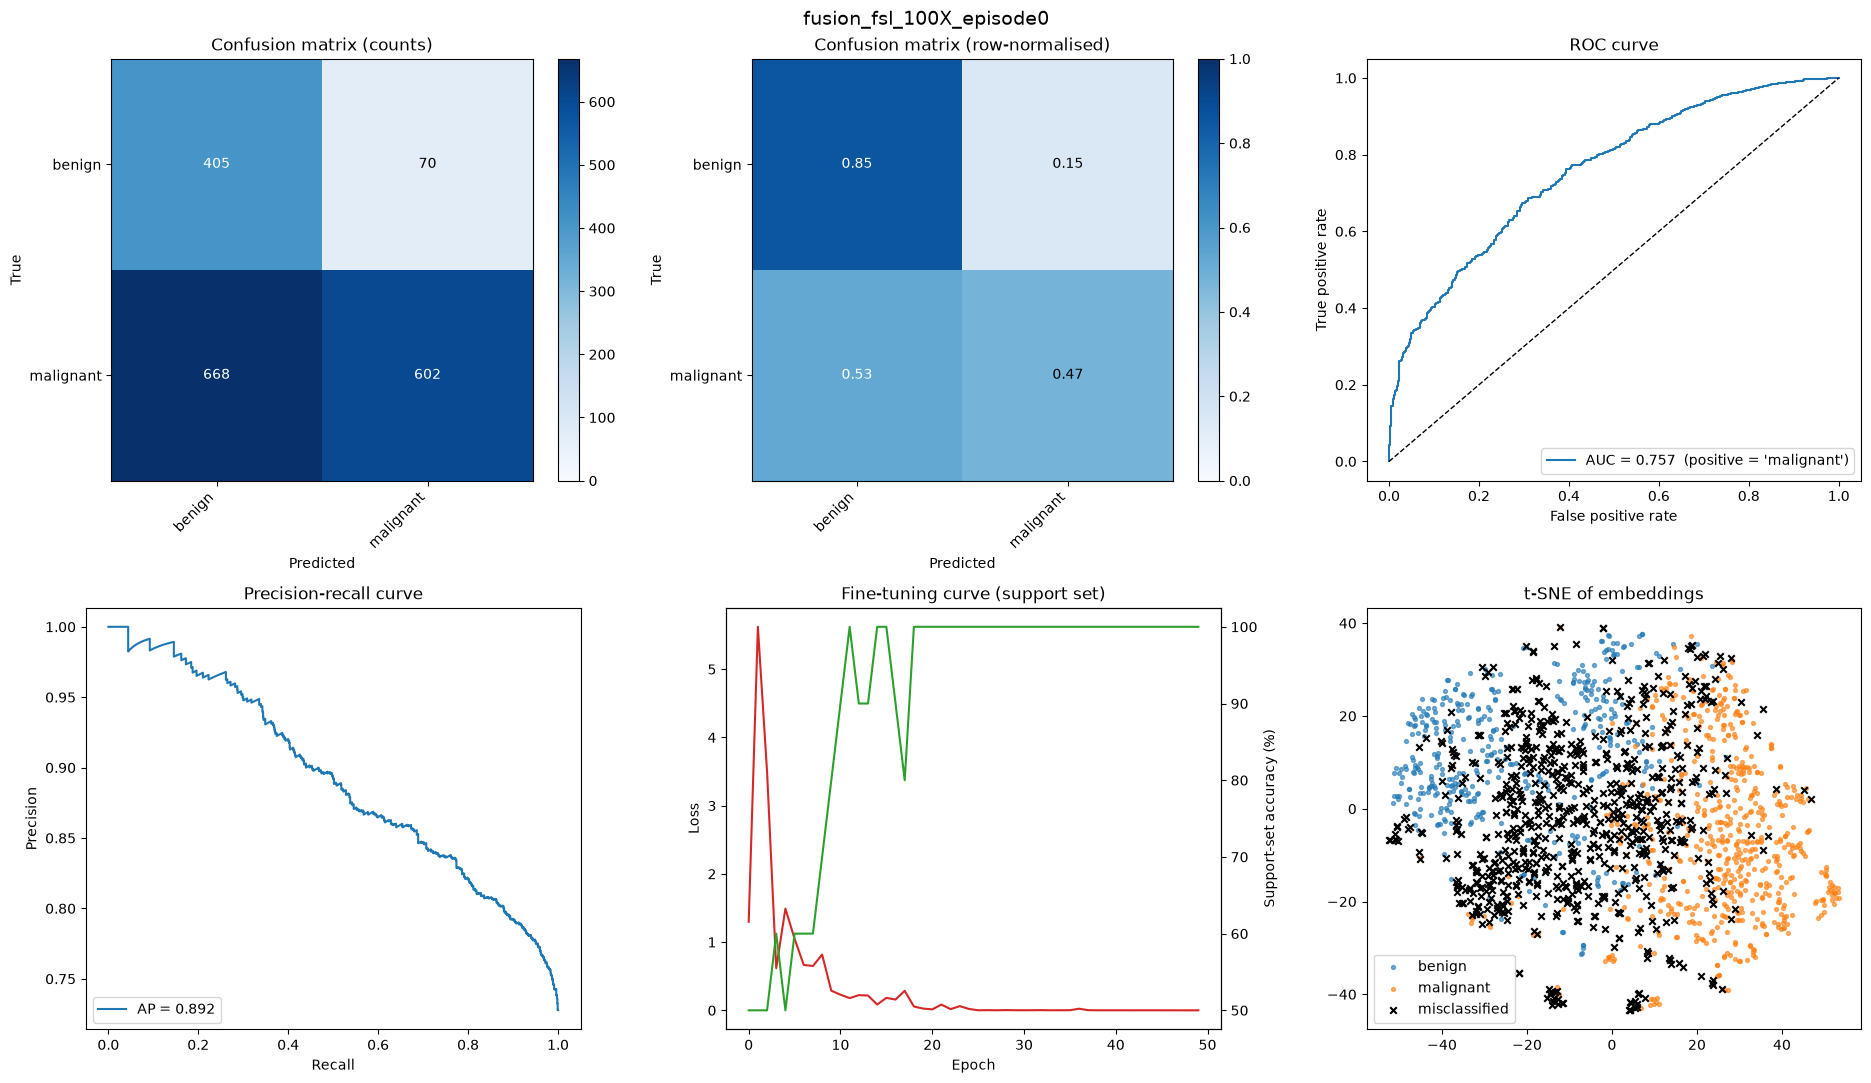


----- fusion_fsl_100X_episode0: modality ablation (ViT-only vs text-only vs fused) -----
       accuracy  f1_macro  roc_auc     mcc  test_only_accuracy  test_only_roc_auc
vit      0.6413    0.6233   0.7705  0.3271              0.7077             0.8236
text     0.4178    0.4081   0.4860 -0.0841              0.4456             0.5099
fused    0.5771    0.5716   0.7571  0.2988              0.6364             0.8175


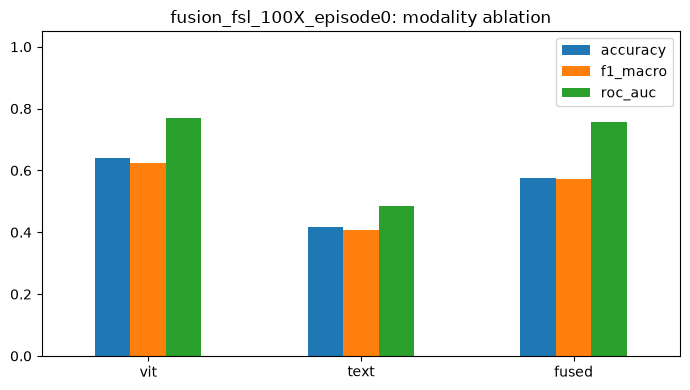


===== fusion_fsl_100X: summary over 1 episode(s) =====
                                     mean  std
accuracy                           0.5771  0.0
balanced_accuracy                  0.6633  0.0
precision_macro                    0.6366  0.0
recall_macro                       0.6633  0.0
f1_macro                           0.5716  0.0
f1_weighted                        0.5937  0.0
mcc                                0.2988  0.0
cohen_kappa                        0.2343  0.0
roc_auc                            0.7571  0.0
sensitivity                        0.4740  0.0
specificity                        0.8526  0.0
avg_precision                      0.8921  0.0
majority_class_baseline            0.7278  0.0
test_only_accuracy                 0.6364  0.0
test_only_balanced_accuracy        0.7022  0.0
test_only_f1_macro                 0.6290  0.0
test_only_roc_auc                  0.8175  0.0
test_only_majority_class_baseline  0.7112  0.0

##################################################

Generating texts: 100%|██████████| 1/1 [00:00<00:00, 25.96it/s]


Generating query set texts...


Generating texts: 100%|██████████| 37/37 [00:03<00:00, 10.70it/s]


Generating test set texts...


Generating texts: 100%|██████████| 18/18 [00:01<00:00, 11.33it/s]


Example generated descriptions: ['fibrous stromal tissue, homogeneous pink-stained cytoplasm, densely packed epithelial cells, smooth, rounded cell borders', 'fibrous stromal tissue, homogeneous pink-stained cytoplasm, densely packed epithelial cells, smooth, rounded cell borders']
Encoding texts...
Training model on support set...
  epoch 10/50 - loss 0.3414 - support-set acc 70.0%
  epoch 20/50 - loss 0.0122 - support-set acc 100.0%
  epoch 30/50 - loss 0.0003 - support-set acc 100.0%
  epoch 40/50 - loss 0.0002 - support-set acc 100.0%
  epoch 50/50 - loss 0.0001 - support-set acc 100.0%
Extracting fused support set features...


Extracting fused query set features...


Extracting fused test set features...



----- fusion_fsl_200X_episode0 -----
              precision    recall  f1-score   support

      benign      0.369     0.409     0.388       492
   malignant      0.760     0.728     0.743      1264

    accuracy                          0.638      1756
   macro avg      0.564     0.568     0.566      1756
weighted avg      0.650     0.638     0.644      1756

                  accuracy: 0.6384
         balanced_accuracy: 0.5682
           precision_macro: 0.5643
              recall_macro: 0.5682
                  f1_macro: 0.5655
               f1_weighted: 0.6438
                       mcc: 0.1324
               cohen_kappa: 0.1320
                   roc_auc: 0.6235
               sensitivity: 0.7278
               specificity: 0.4085
             avg_precision: 0.8063
             accuracy_ci95: [0.6173, 0.6606]
              roc_auc_ci95: [0.5957, 0.6526]
   majority_class_baseline: 0.7198
        test_only_accuracy: 0.6690
  test_only_balanced_accuracy: 0.6065
        test_only

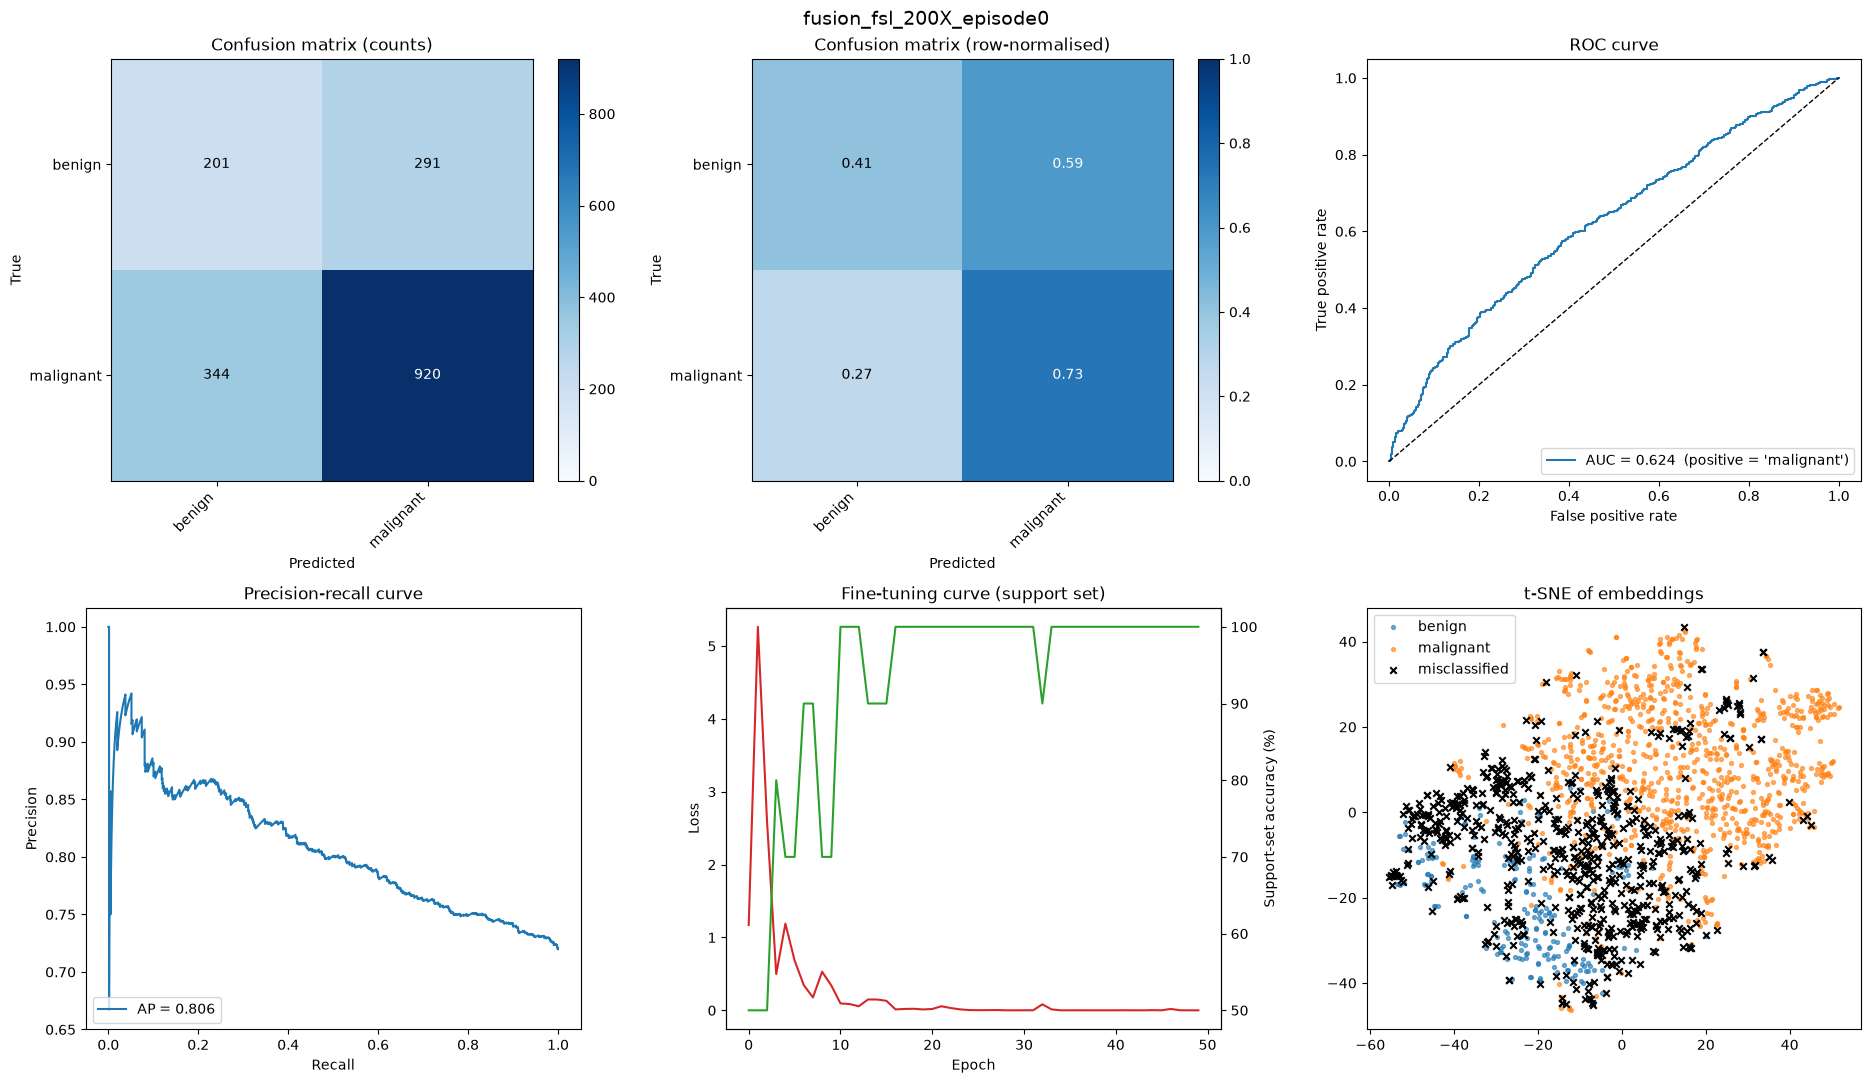


----- fusion_fsl_200X_episode0: modality ablation (ViT-only vs text-only vs fused) -----
       accuracy  f1_macro  roc_auc     mcc  test_only_accuracy  test_only_roc_auc
vit      0.6099    0.5612   0.6212  0.1374              0.6324             0.6630
text     0.4664    0.4625   0.5763  0.0595              0.4826             0.5681
fused    0.6384    0.5655   0.6235  0.1324              0.6690             0.6850


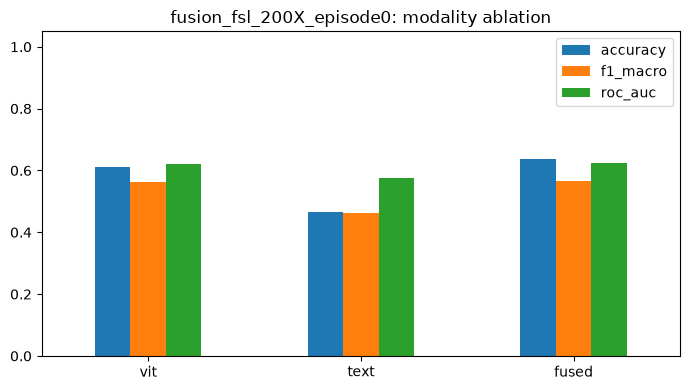


===== fusion_fsl_200X: summary over 1 episode(s) =====
                                     mean  std
accuracy                           0.6384  0.0
balanced_accuracy                  0.5682  0.0
precision_macro                    0.5643  0.0
recall_macro                       0.5682  0.0
f1_macro                           0.5655  0.0
f1_weighted                        0.6438  0.0
mcc                                0.1324  0.0
cohen_kappa                        0.1320  0.0
roc_auc                            0.6235  0.0
sensitivity                        0.7278  0.0
specificity                        0.4085  0.0
avg_precision                      0.8063  0.0
majority_class_baseline            0.7198  0.0
test_only_accuracy                 0.6690  0.0
test_only_balanced_accuracy        0.6065  0.0
test_only_f1_macro                 0.6030  0.0
test_only_roc_auc                  0.6850  0.0
test_only_majority_class_baseline  0.7178  0.0

##################################################

Generating texts: 100%|██████████| 1/1 [00:00<00:00, 28.22it/s]


Generating query set texts...


Generating texts: 100%|██████████| 35/35 [00:02<00:00, 13.11it/s]


Generating test set texts...


Generating texts: 100%|██████████| 16/16 [00:01<00:00, 10.20it/s]


Example generated descriptions: ['homogeneous pink-stained cytoplasm, fibrous stromal tissue, clear cell boundaries with visible nucleoli, densely packed epithelial cells', 'homogeneous pink-stained cytoplasm, fibrous stromal tissue, irregular and enlarged nuclei, smooth, rounded cell borders']
Encoding texts...
Training model on support set...
  epoch 10/50 - loss 1.0771 - support-set acc 70.0%
  epoch 20/50 - loss 0.1489 - support-set acc 90.0%
  epoch 30/50 - loss 0.0072 - support-set acc 100.0%
  epoch 40/50 - loss 0.0104 - support-set acc 100.0%
  epoch 50/50 - loss 0.0012 - support-set acc 100.0%
Extracting fused support set features...


Extracting fused query set features...


Extracting fused test set features...



----- fusion_fsl_400X_episode0 -----
              precision    recall  f1-score   support

      benign      0.559     0.487     0.521       468
   malignant      0.800     0.842     0.821      1140

    accuracy                          0.739      1608
   macro avg      0.679     0.665     0.671      1608
weighted avg      0.730     0.739     0.733      1608

                  accuracy: 0.7388
         balanced_accuracy: 0.6646
           precision_macro: 0.6794
              recall_macro: 0.6646
                  f1_macro: 0.6705
               f1_weighted: 0.7332
                       mcc: 0.3437
               cohen_kappa: 0.3422
                   roc_auc: 0.7659
               sensitivity: 0.8421
               specificity: 0.4872
             avg_precision: 0.8833
             accuracy_ci95: [0.7170, 0.7612]
              roc_auc_ci95: [0.7384, 0.7918]
   majority_class_baseline: 0.7090
        test_only_accuracy: 0.7347
  test_only_balanced_accuracy: 0.6900
        test_only

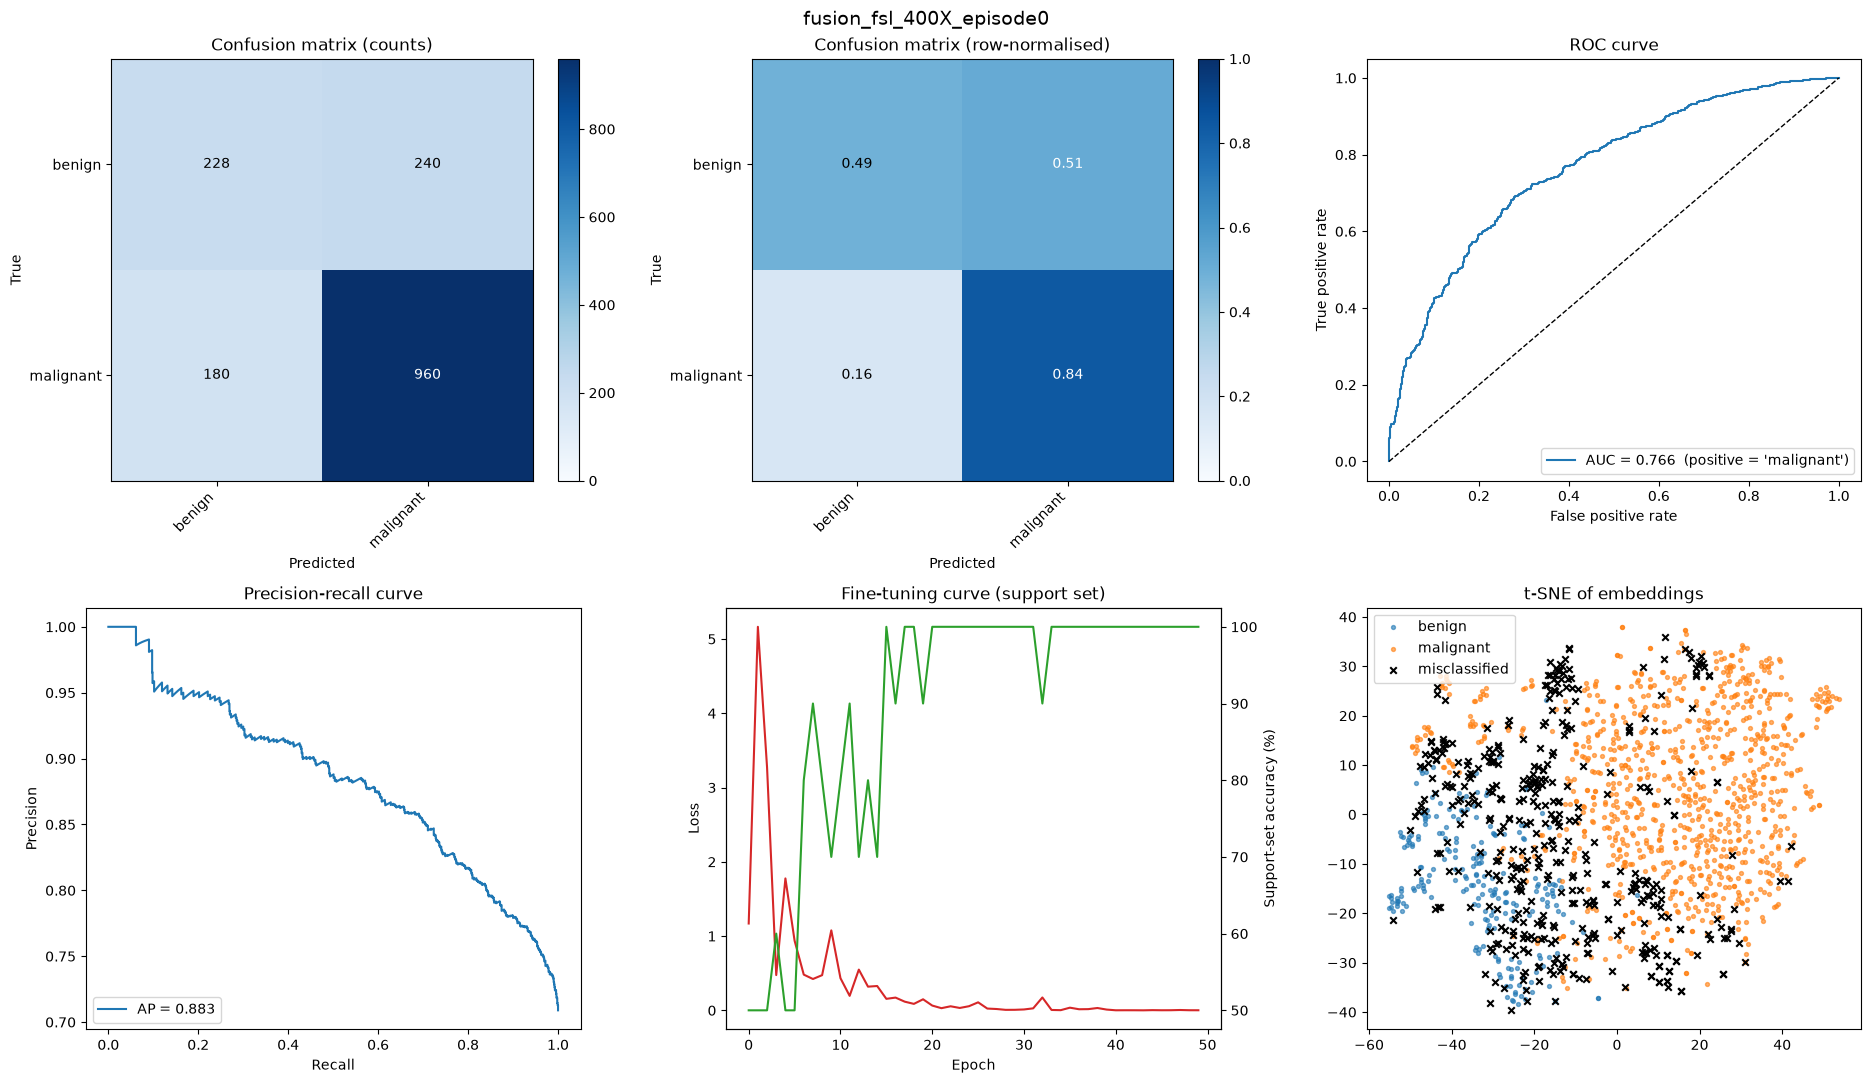


----- fusion_fsl_400X_episode0: modality ablation (ViT-only vs text-only vs fused) -----
       accuracy  f1_macro  roc_auc     mcc  test_only_accuracy  test_only_roc_auc
vit      0.7121    0.6808   0.7736  0.3796              0.7307             0.8077
text     0.5983    0.5497   0.5576  0.1096              0.5485             0.4842
fused    0.7388    0.6705   0.7659  0.3437              0.7347             0.7974


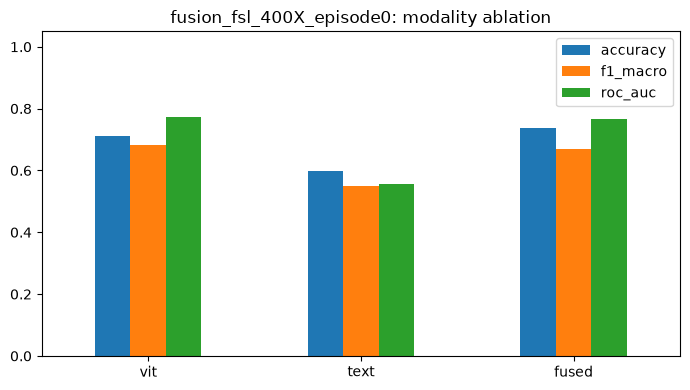


===== fusion_fsl_400X: summary over 1 episode(s) =====
                                     mean  std
accuracy                           0.7388  0.0
balanced_accuracy                  0.6646  0.0
precision_macro                    0.6794  0.0
recall_macro                       0.6646  0.0
f1_macro                           0.6705  0.0
f1_weighted                        0.7332  0.0
mcc                                0.3437  0.0
cohen_kappa                        0.3422  0.0
roc_auc                            0.7659  0.0
sensitivity                        0.8421  0.0
specificity                        0.4872  0.0
avg_precision                      0.8833  0.0
majority_class_baseline            0.7090  0.0
test_only_accuracy                 0.7347  0.0
test_only_balanced_accuracy        0.6900  0.0
test_only_f1_macro                 0.6893  0.0
test_only_roc_auc                  0.7974  0.0
test_only_majority_class_baseline  0.6931  0.0

##################################################

Generating texts: 100%|██████████| 1/1 [00:00<00:00, 29.59it/s]


Generating query set texts...


Generating texts: 100%|██████████| 146/146 [00:14<00:00, 10.41it/s]


Generating test set texts...


Generating texts: 100%|██████████| 69/69 [00:06<00:00, 10.36it/s]


Example generated descriptions: ['fibrous stromal tissue, homogeneous pink-stained cytoplasm, densely packed epithelial cells, smooth, rounded cell borders', 'fibrous stromal tissue, smooth, rounded cell borders, homogeneous pink-stained cytoplasm, irregular and enlarged nuclei']
Encoding texts...
Training model on support set...
  epoch 10/50 - loss 0.5840 - support-set acc 80.0%
  epoch 20/50 - loss 0.1540 - support-set acc 90.0%
  epoch 30/50 - loss 0.0031 - support-set acc 100.0%
  epoch 40/50 - loss 0.0026 - support-set acc 100.0%
  epoch 50/50 - loss 0.0010 - support-set acc 100.0%
Extracting fused support set features...


Extracting fused query set features...


Extracting fused test set features...



----- fusion_fsl_40X_100X_200X_400X_episode0 -----
              precision    recall  f1-score   support

      benign      0.420     0.661     0.514      1819
   malignant      0.845     0.670     0.747      5025

    accuracy                          0.667      6844
   macro avg      0.633     0.665     0.630      6844
weighted avg      0.732     0.667     0.685      6844

                  accuracy: 0.6673
         balanced_accuracy: 0.6652
           precision_macro: 0.6325
              recall_macro: 0.6652
                  f1_macro: 0.6304
               f1_weighted: 0.6851
                       mcc: 0.2959
               cohen_kappa: 0.2794
                   roc_auc: 0.7383
               sensitivity: 0.6697
               specificity: 0.6608
             avg_precision: 0.8892
             accuracy_ci95: [0.6553, 0.6784]
              roc_auc_ci95: [0.7256, 0.7507]
   majority_class_baseline: 0.7342
        test_only_accuracy: 0.6898
  test_only_balanced_accuracy: 0.7088
   

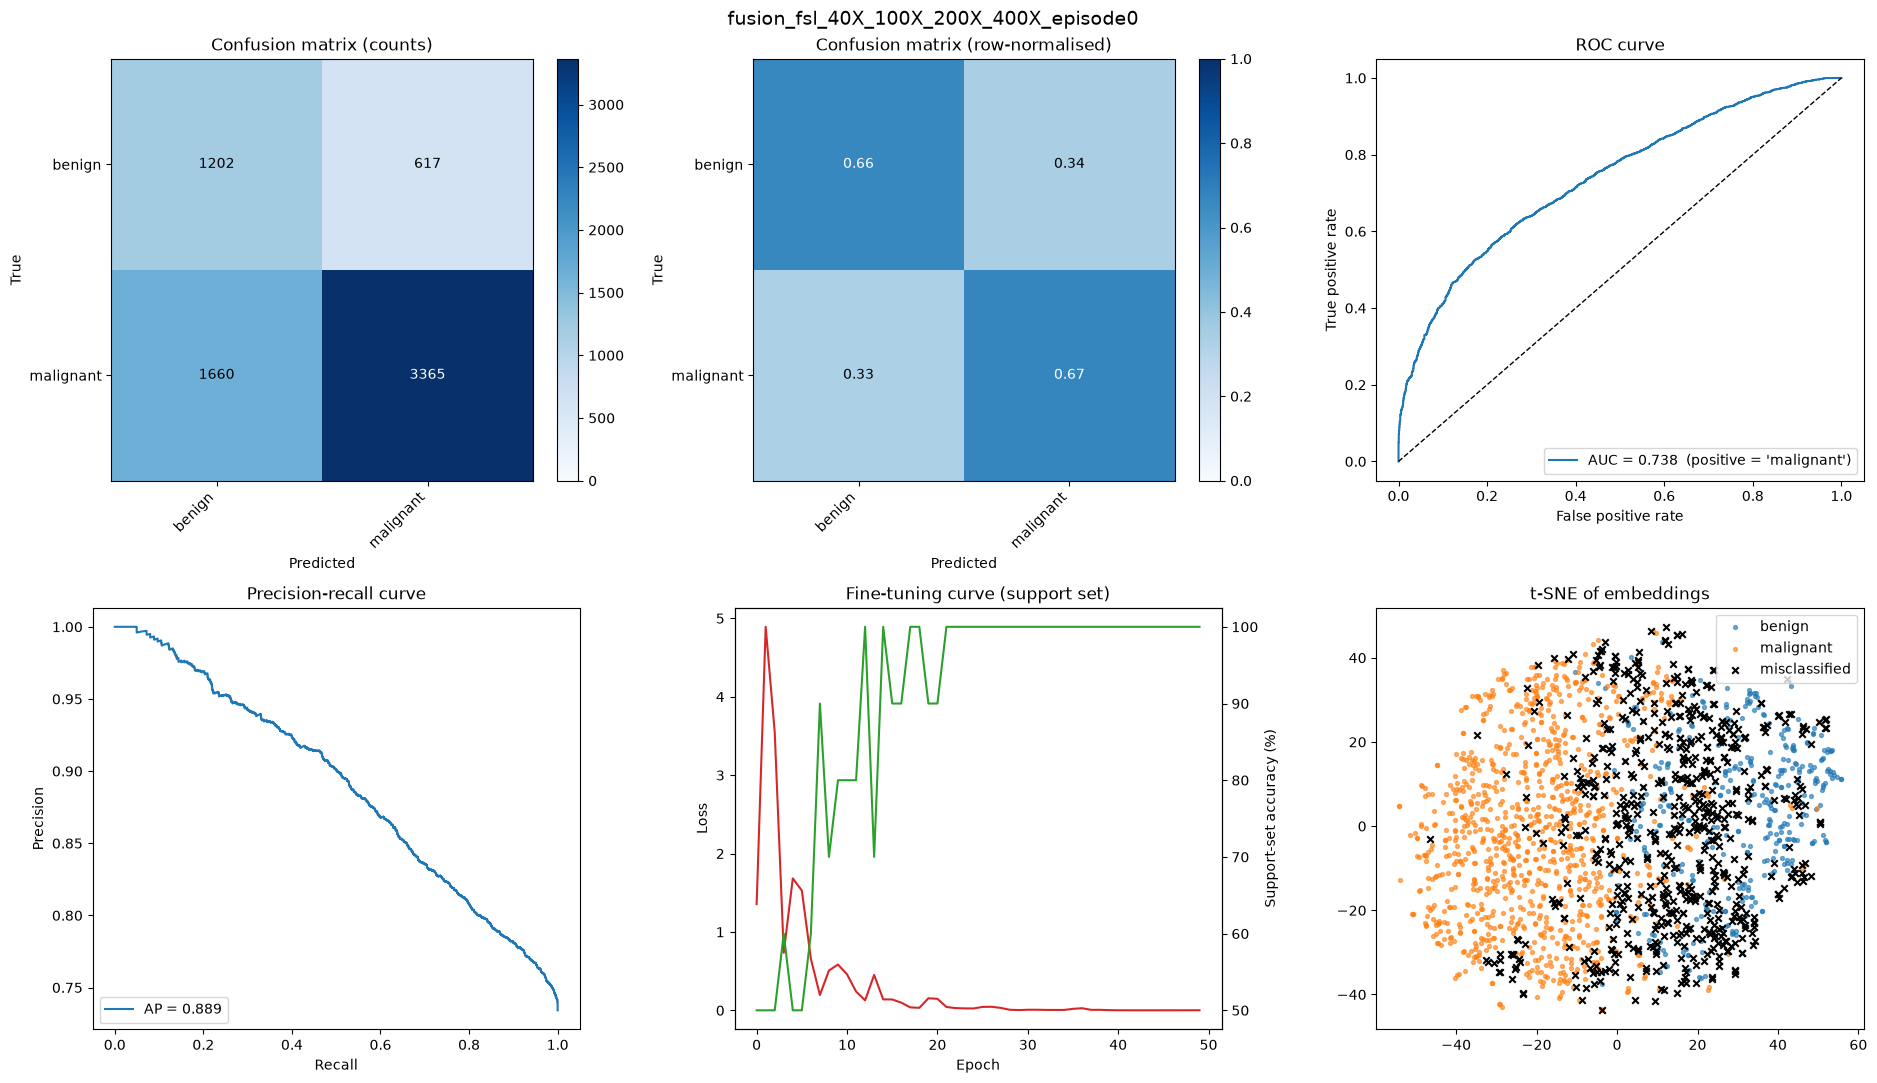


----- fusion_fsl_40X_100X_200X_400X_episode0: modality ablation (ViT-only vs text-only vs fused) -----
       accuracy  f1_macro  roc_auc     mcc  test_only_accuracy  test_only_roc_auc
vit      0.6742    0.6284   0.7315  0.2782              0.6930             0.7715
text     0.4151    0.4127   0.4796 -0.0119              0.4367             0.5148
fused    0.6673    0.6304   0.7383  0.2959              0.6898             0.7813


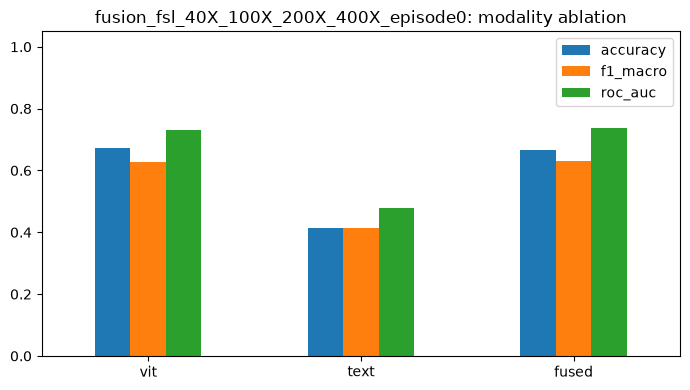


===== fusion_fsl_40X_100X_200X_400X: summary over 1 episode(s) =====
                                     mean  std
accuracy                           0.6673  0.0
balanced_accuracy                  0.6652  0.0
precision_macro                    0.6325  0.0
recall_macro                       0.6652  0.0
f1_macro                           0.6304  0.0
f1_weighted                        0.6851  0.0
mcc                                0.2959  0.0
cohen_kappa                        0.2794  0.0
roc_auc                            0.7383  0.0
sensitivity                        0.6697  0.0
specificity                        0.6608  0.0
avg_precision                      0.8892  0.0
majority_class_baseline            0.7342  0.0
test_only_accuracy                 0.6898  0.0
test_only_balanced_accuracy        0.7088  0.0
test_only_f1_macro                 0.6664  0.0
test_only_roc_auc                  0.7813  0.0
test_only_majority_class_baseline  0.7177  0.0

===== Comparison across magnificatio

In [10]:
TAG_PREFIX = "fusion_fsl"
all_setting_summaries = {}

for setting in MAGNIFICATION_SETTINGS:
    print("\n" + "#" * 72 + f"\n# Magnification setting: {setting}\n" + "#" * 72)
    data_dir = prepare_breakhis_split(RAW_DATA_DIR, PREPARED_ROOT, setting, TEST_FRACTION, SPLIT_SEED)
    verify_and_report_split(data_dir)
    train_dataset_vit_aug, train_dataset_vit_eval, test_dataset_vit, train_dataset_clip, test_dataset_clip, class_names = load_datasets(data_dir)
    print(f"Classes: {class_names}")
    safe = setting.replace("+", "_")
    episode_metrics = []

    for episode in range(N_EPISODES):
        seed = BASE_SEED + episode
        print(f"\n=== [{setting}] Episode {episode + 1}/{N_EPISODES} (seed={seed}) ===")
        set_seed(seed)
        rng = np.random.RandomState(seed)

        support_indices, query_indices = create_support_and_query(train_dataset_vit_eval, SHOTS_PER_CLASS, rng)
        print(f"support: {len(support_indices)} images | query: {len(query_indices)} images (patient-disjoint from support)")

        support_set_vit = Subset(train_dataset_vit_aug, support_indices)        # augmented, for training
        support_set_vit_eval = Subset(train_dataset_vit_eval, support_indices)  # clean, for prototype embeddings
        query_set_vit = Subset(train_dataset_vit_eval, query_indices)
        support_set_clip = Subset(train_dataset_clip, support_indices)
        query_set_clip = Subset(train_dataset_clip, query_indices)

        support_labels = np.array([label for _, label in support_set_vit_eval])

        text_bank = build_clip_text_bank()
        print("Generating support set texts...")
        support_texts = generate_texts(support_set_clip, text_bank)
        print("Generating query set texts...")
        query_texts = generate_texts(query_set_clip, text_bank)
        print("Generating test set texts...")
        test_texts = generate_texts(test_dataset_clip, text_bank)
        print("Example generated descriptions:", support_texts[:2])

        print("Encoding texts...")
        support_text_features = encode_texts(support_texts)
        query_text_features = encode_texts(query_texts)
        test_text_features = encode_texts(test_texts)

        g = torch.Generator().manual_seed(seed)
        support_loader = DataLoader(support_set_vit, batch_size=min(BATCH_SIZE, len(support_set_vit)), shuffle=True, generator=g)

        model = build_vit_model()
        if FREEZE_BACKBONE:
            freeze_backbone_except_last_block(model, unfreeze_last_n_blocks=1)

        print("Training model on support set...")
        model, history = train_model_on_support(model, support_loader, NUM_EPOCHS, LEARNING_RATE, WEIGHT_DECAY)

        os.makedirs("checkpoints", exist_ok=True)
        torch.save(model.state_dict(), f"checkpoints/fusion_vit_{safe}_episode{episode}.pt")  # Fix (checkpointing)

        support_eval_loader = DataLoader(support_set_vit_eval, batch_size=EXTRACT_BATCH_SIZE, shuffle=False)
        query_loader = DataLoader(query_set_vit, batch_size=EXTRACT_BATCH_SIZE, shuffle=False)
        test_loader = DataLoader(test_dataset_vit, batch_size=EXTRACT_BATCH_SIZE, shuffle=False)

        print("Extracting fused support set features...")
        support_fused, _, support_vit = extract_fused_features(model, support_eval_loader, support_text_features, support_labels)
        print("Extracting fused query set features...")
        query_fused, query_labels, query_vit = extract_fused_features(model, query_loader, query_text_features)
        print("Extracting fused test set features...")
        test_fused, test_labels, test_vit = extract_fused_features(model, test_loader, test_text_features)

        y_true, y_pred, sims, feats, n_query = evaluate_fused(
            support_fused, support_labels, query_fused, query_labels, test_fused, test_labels
        )
        metrics = full_analysis(
            y_true, y_pred, similarities_to_probs(sims), class_names,
            tag=f"fusion_fsl_{safe}_episode{episode}", features=feats, history=history, n_query=n_query,
        )
        episode_metrics.append(metrics)

        modality_ablation(
            {"vit": support_vit, "text": support_text_features, "fused": support_fused},
            {"vit": query_vit, "text": query_text_features, "fused": query_fused},
            {"vit": test_vit, "text": test_text_features, "fused": test_fused},
            support_labels, y_true, n_query, class_names, tag=f"fusion_fsl_{safe}_episode{episode}",
        )

    all_setting_summaries[setting] = summarize_episodes(episode_metrics, f"fusion_fsl_{safe}")

comparison = pd.DataFrame({s: sm["mean"] for s, sm in all_setting_summaries.items()}).T
cols = [c for c in ["accuracy", "majority_class_baseline", "balanced_accuracy", "f1_macro", "roc_auc", "mcc",
                    "test_only_accuracy", "test_only_majority_class_baseline", "test_only_roc_auc"] if c in comparison.columns]
print("\n===== Comparison across magnification settings (mean over episodes) =====")
print(comparison[cols].round(4).to_string())
comparison[cols].to_csv(f"{RESULTS_DIR}/{TAG_PREFIX}_magnification_comparison.csv")
